# Day 059 | CPT Data Interpretation with ML

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** YYYY-MM-DD  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| CPT Data | Cone Penetration Test measurements | qc, fs, u2 at each depth |
| Robertson Zones | Soil behavior type from CPT charts | 9 zones from sensitive clay to sand |
| Soil Behavior Type Index (Ic) | Numerical CPT-based soil index | Ic < 1.31 (gravel) to Ic > 3.6 (organic) |
| ML Classification | Predict Robertson zone from CPT features | Automate chart-based interpretation |
| Multi-class Evaluation | Per-zone accuracy and confusion | Which zones are hardest to distinguish? |
| CPT Profile Visualization | Depth vs parameters with zone coloring | Standard geotechnical CPT log |

---

## Our Geotechnical Problem

The **Cone Penetration Test (CPT)** provides continuous subsurface profiling.  
Engineers classify soil behavior using **Robertson (1990) charts** based on normalized cone resistance and friction ratio.  
Can ML automate and potentially improve this classification?

| Robertson Zone | Soil Behavior Type |
|:-:|---|
| 3 | Clay - sensitive fine grained |
| 4 | Silt mixtures - clayey silt to silty clay |
| 5 | Sand mixtures - silty sand to sandy silt |
| 6 | Sand - clean sand to silty sand |
| 7 | Gravelly sand to dense sand |
| 8 | Very stiff sand to clayey sand |
| 9 | Very stiff fine grained |

---

## Part 1: Load and Explore CPT Data

In [1]:
# ─────────────────────────────────────────────────────
# LOAD AND EXPLORE CPT DATA
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('cpt_data.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nRobertson zone distribution:")
print(df['robertson_zone'].value_counts().sort_index())
print(f"\nDescriptive statistics:")
print(df.describe().round(2))

Dataset shape: (200, 8)

Columns: ['depth', 'cone_resistance_qc', 'sleeve_friction_fs', 'pore_pressure_u2', 'friction_ratio', 'normalized_qc', 'soil_behavior_type_index_Ic', 'robertson_zone']

Robertson zone distribution:
robertson_zone
3    31
4    26
5    27
6    26
7    26
8    31
9    33
Name: count, dtype: int64

Descriptive statistics:
        depth  cone_resistance_qc  sleeve_friction_fs  pore_pressure_u2  \
count  200.00              200.00              200.00            200.00   
mean    13.17               12.30                0.17            104.53   
std      7.07               10.62                0.13             86.00   
min      0.70                0.53                0.01             -9.90   
25%      6.95                3.44                0.08             43.20   
50%     13.70                9.34                0.14             84.70   
75%     19.80               18.65                0.25            142.20   
max     24.90               39.72                0.53   

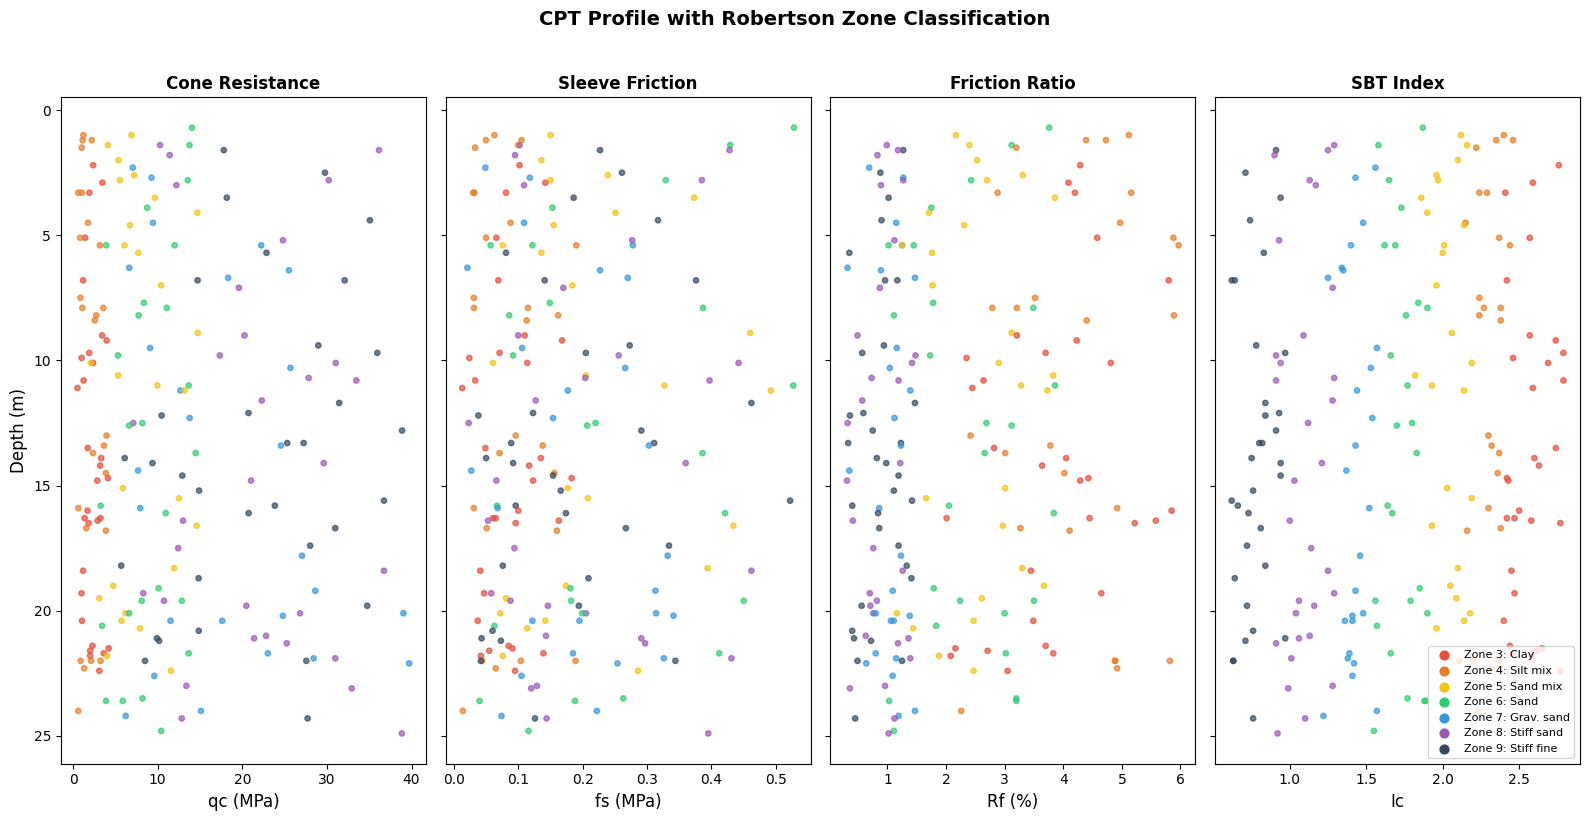

In [2]:
# ─────────────────────────────────────────────────────
# CPT PROFILE VISUALIZATION
# ─────────────────────────────────────────────────────

# Sort by depth for profile view
df_sorted = df.sort_values('depth')

fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharey=True)

zone_colors = {3: '#e74c3c', 4: '#e67e22', 5: '#f1c40f',
               6: '#2ecc71', 7: '#3498db', 8: '#9b59b6', 9: '#34495e'}
zone_names = {3: 'Clay', 4: 'Silt mix', 5: 'Sand mix',
              6: 'Sand', 7: 'Grav. sand', 8: 'Stiff sand', 9: 'Stiff fine'}

colors = [zone_colors.get(z, 'gray') for z in df_sorted['robertson_zone']]

# qc profile
axes[0].scatter(df_sorted['cone_resistance_qc'], df_sorted['depth'],
                c=colors, s=15, alpha=0.7)
axes[0].set_xlabel('qc (MPa)', fontsize=12)
axes[0].set_ylabel('Depth (m)', fontsize=12)
axes[0].set_title('Cone Resistance', fontsize=12, fontweight='bold')
axes[0].invert_yaxis()

# fs profile
axes[1].scatter(df_sorted['sleeve_friction_fs'], df_sorted['depth'],
                c=colors, s=15, alpha=0.7)
axes[1].set_xlabel('fs (MPa)', fontsize=12)
axes[1].set_title('Sleeve Friction', fontsize=12, fontweight='bold')

# Friction ratio
axes[2].scatter(df_sorted['friction_ratio'], df_sorted['depth'],
                c=colors, s=15, alpha=0.7)
axes[2].set_xlabel('Rf (%)', fontsize=12)
axes[2].set_title('Friction Ratio', fontsize=12, fontweight='bold')

# Ic profile
axes[3].scatter(df_sorted['soil_behavior_type_index_Ic'], df_sorted['depth'],
                c=colors, s=15, alpha=0.7)
axes[3].set_xlabel('Ic', fontsize=12)
axes[3].set_title('SBT Index', fontsize=12, fontweight='bold')

# Legend
for zone, color in zone_colors.items():
    axes[3].scatter([], [], c=color, s=40, label=f'Zone {zone}: {zone_names[zone]}')
axes[3].legend(fontsize=8, loc='lower right')

plt.suptitle('CPT Profile with Robertson Zone Classification',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## Part 2: Robertson Classification Chart

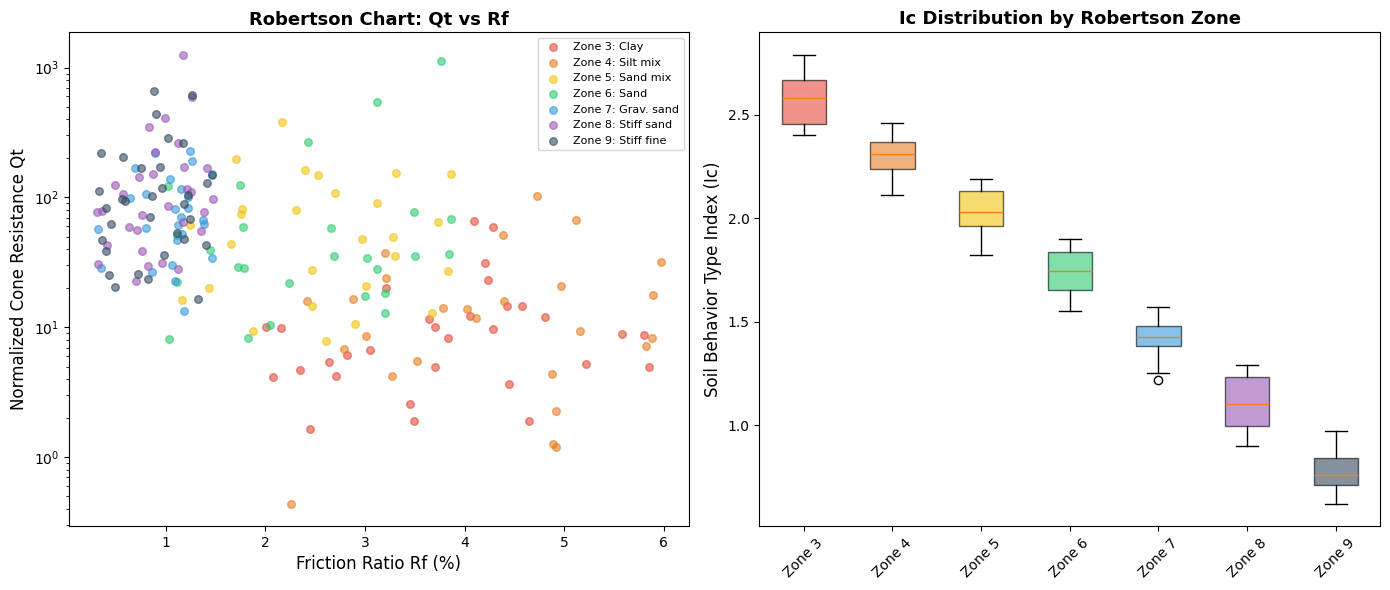

Ic values generally decrease from clay (high Ic) to sand/gravel (low Ic).
Overlapping Ic ranges between adjacent zones make classification challenging.


In [3]:
# ─────────────────────────────────────────────────────
# ROBERTSON CLASSIFICATION CHART
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Qt vs Rf chart (Robertson 1990 style)
for zone in sorted(df['robertson_zone'].unique()):
    mask = df['robertson_zone'] == zone
    axes[0].scatter(df.loc[mask, 'friction_ratio'],
                     df.loc[mask, 'normalized_qc'],
                     alpha=0.6, s=30, color=zone_colors.get(zone, 'gray'),
                     label=f'Zone {zone}: {zone_names.get(zone, "")}')
axes[0].set_xlabel('Friction Ratio Rf (%)', fontsize=12)
axes[0].set_ylabel('Normalized Cone Resistance Qt', fontsize=12)
axes[0].set_title('Robertson Chart: Qt vs Rf', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=8)
axes[0].set_yscale('log')

# Ic distribution by zone
zones_sorted = sorted(df['robertson_zone'].unique())
ic_by_zone = [df.loc[df['robertson_zone'] == z, 'soil_behavior_type_index_Ic'].values
              for z in zones_sorted]
bp = axes[1].boxplot(ic_by_zone, labels=[f'Zone {z}' for z in zones_sorted],
                      patch_artist=True)
for patch, zone in zip(bp['boxes'], zones_sorted):
    patch.set_facecolor(zone_colors.get(zone, 'gray'))
    patch.set_alpha(0.6)
axes[1].set_ylabel('Soil Behavior Type Index (Ic)', fontsize=12)
axes[1].set_title('Ic Distribution by Robertson Zone', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Ic values generally decrease from clay (high Ic) to sand/gravel (low Ic).")
print("Overlapping Ic ranges between adjacent zones make classification challenging.")

---

## Part 3: Prepare Features and Train Classifiers

In [4]:
# ─────────────────────────────────────────────────────
# FEATURE PREPARATION AND MODEL TRAINING
# ─────────────────────────────────────────────────────

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

features = ['depth', 'cone_resistance_qc', 'sleeve_friction_fs',
            'pore_pressure_u2', 'friction_ratio', 'normalized_qc',
            'soil_behavior_type_index_Ic']

X = df[features]
y = df['robertson_zone']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

classifiers = {
    'Logistic Reg': LogisticRegression(max_iter=2000),  # multinomial by default in sklearn >= 1.5
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', C=10, gamma='scale'),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=6, random_state=42)
}

results = {}
preds = {}
for name, clf in classifiers.items():
    clf.fit(X_train_s, y_train)
    y_pred = clf.predict(X_test_s)
    preds[name] = y_pred
    cv = cross_val_score(clf, X_train_s, y_train, cv=5, scoring='accuracy')
    results[name] = {
        'CV Accuracy': cv.mean(),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
        'F1 (weighted)': f1_score(y_test, y_pred, average='weighted')
    }

results_df = pd.DataFrame(results).T.round(4).sort_values('Test Accuracy', ascending=False)
print("Classifier Comparison for Robertson Zone Prediction:")
print("=" * 65)
print(results_df)

Classifier Comparison for Robertson Zone Prediction:
                   CV Accuracy  Test Accuracy  F1 (macro)  F1 (weighted)
Gradient Boosting       0.8062          0.950      0.9506         0.9493
Random Forest           0.8625          0.925      0.9289         0.9246
SVM                     0.7625          0.775      0.7596         0.7634
Logistic Reg            0.6812          0.650      0.6214         0.6357
KNN                     0.4625          0.500      0.4877         0.4982


---

## Part 4: Confusion Matrix — Zone Misclassification

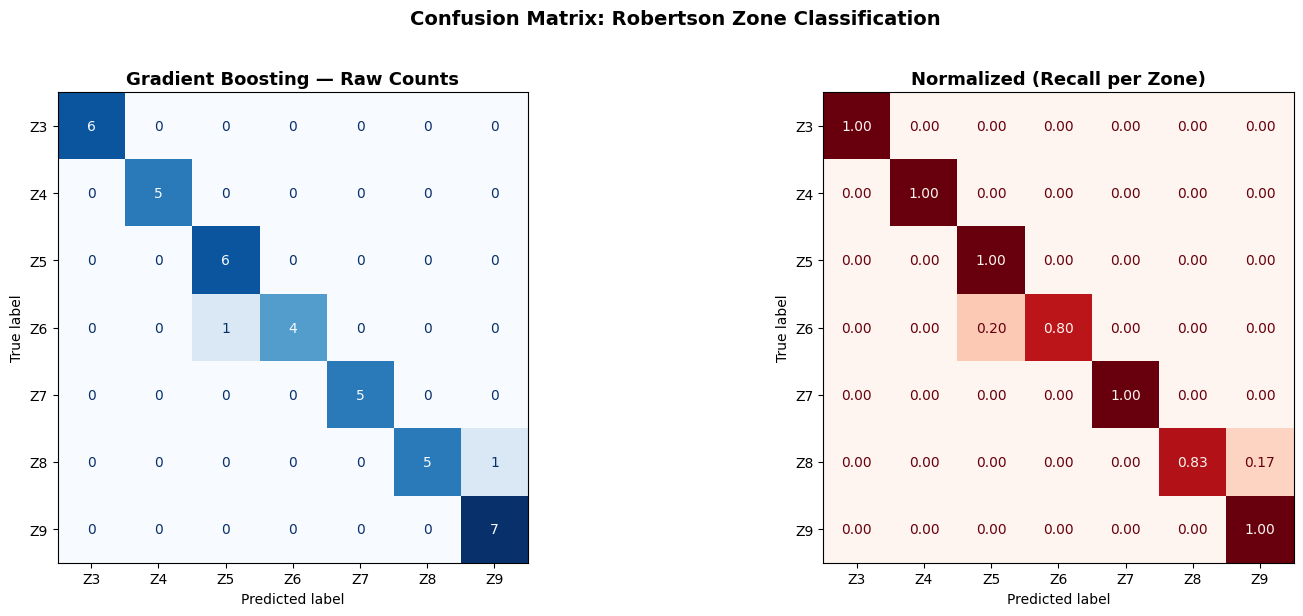


Classification Report (Gradient Boosting):
                     precision    recall  f1-score   support

      Zone 3 (Clay)       1.00      1.00      1.00         6
  Zone 4 (Silt mix)       1.00      1.00      1.00         5
  Zone 5 (Sand mix)       0.86      1.00      0.92         6
      Zone 6 (Sand)       1.00      0.80      0.89         5
Zone 7 (Grav. sand)       1.00      1.00      1.00         5
Zone 8 (Stiff sand)       1.00      0.83      0.91         6
Zone 9 (Stiff fine)       0.88      1.00      0.93         7

           accuracy                           0.95        40
          macro avg       0.96      0.95      0.95        40
       weighted avg       0.96      0.95      0.95        40



In [5]:
# ─────────────────────────────────────────────────────
# CONFUSION MATRIX FOR ROBERTSON ZONES
# ─────────────────────────────────────────────────────

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

best_name = results_df.index[0]
y_pred_best = preds[best_name]
zone_labels = sorted(df['robertson_zone'].unique())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm = confusion_matrix(y_test, y_pred_best, labels=zone_labels)
zone_display = [f'Z{z}' for z in zone_labels]

ConfusionMatrixDisplay(cm, display_labels=zone_display).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title(f'{best_name} — Raw Counts', fontsize=13, fontweight='bold')

# Normalized
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
ConfusionMatrixDisplay(cm_norm, display_labels=zone_display).plot(
    ax=axes[1], cmap='Reds', colorbar=False, values_format='.2f'
)
axes[1].set_title('Normalized (Recall per Zone)', fontsize=13, fontweight='bold')

plt.suptitle('Confusion Matrix: Robertson Zone Classification',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"\nClassification Report ({best_name}):")
zone_target_names = [f'Zone {z} ({zone_names[z]})' for z in zone_labels]
print(classification_report(y_test, y_pred_best, labels=zone_labels,
                            target_names=zone_target_names))

---

## Part 5: Feature Importance for CPT Classification

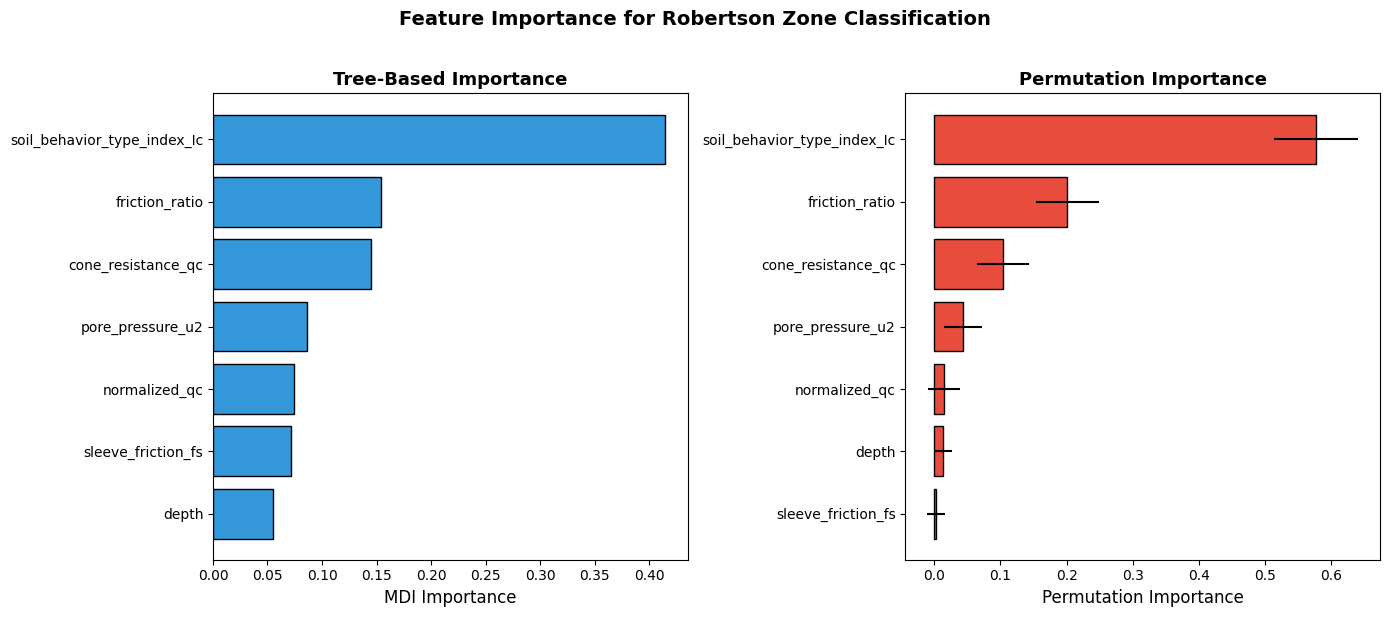

Key CPT parameters for zone classification:
  Ic:    Soil behavior type index (directly defines zones)
  Rf:    Friction ratio (separates clay from sand)
  qc:    Cone resistance (separates stiff from soft)


In [6]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE — Which CPT parameters matter most?
# ─────────────────────────────────────────────────────

from sklearn.inspection import permutation_importance

rf_clf = classifiers['Random Forest']
perm = permutation_importance(rf_clf, X_test_s, y_test, n_repeats=20,
                               random_state=42, scoring='accuracy')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sorted_mdi = np.argsort(rf_clf.feature_importances_)
axes[0].barh(np.array(features)[sorted_mdi], rf_clf.feature_importances_[sorted_mdi],
             color='#3498db', edgecolor='black')
axes[0].set_xlabel('MDI Importance', fontsize=12)
axes[0].set_title('Tree-Based Importance', fontsize=13, fontweight='bold')

sorted_perm = np.argsort(perm.importances_mean)
axes[1].barh(np.array(features)[sorted_perm], perm.importances_mean[sorted_perm],
             color='#e74c3c', edgecolor='black',
             xerr=perm.importances_std[sorted_perm])
axes[1].set_xlabel('Permutation Importance', fontsize=12)
axes[1].set_title('Permutation Importance', fontsize=13, fontweight='bold')

plt.suptitle('Feature Importance for Robertson Zone Classification',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Key CPT parameters for zone classification:")
print("  Ic:    Soil behavior type index (directly defines zones)")
print("  Rf:    Friction ratio (separates clay from sand)")
print("  qc:    Cone resistance (separates stiff from soft)")

---

## Part 6: ML vs Ic-Based Classification

In [7]:
# ─────────────────────────────────────────────────────
# ML vs SIMPLE Ic THRESHOLDS
# ─────────────────────────────────────────────────────

def ic_zone(Ic):
    """Simple Ic-based Robertson zone classification."""
    if Ic > 3.6: return 3   # Sensitive clay
    elif Ic > 2.95: return 4  # Silt mix
    elif Ic > 2.60: return 5  # Sand mix
    elif Ic > 2.05: return 5  # Sand mix
    elif Ic > 1.31: return 6  # Sand
    else: return 7            # Gravelly sand

# Apply Ic-based classification to test set
Ic_test = X_test['soil_behavior_type_index_Ic'].values
y_pred_ic = np.array([ic_zone(ic) for ic in Ic_test])

acc_ic = accuracy_score(y_test, y_pred_ic)
acc_ml = accuracy_score(y_test, y_pred_best)

print("Comparison: Simple Ic Thresholds vs ML")
print("=" * 45)
print(f"  Ic-based accuracy: {acc_ic:.4f}")
print(f"  ML accuracy:       {acc_ml:.4f}")
print(f"  Improvement:       {(acc_ml - acc_ic)*100:.1f} percentage points")
print()
print("ML improves because it uses ALL CPT parameters, not just Ic.")
print("The Ic index alone cannot distinguish all 7 zones reliably.")

Comparison: Simple Ic Thresholds vs ML
  Ic-based accuracy: 0.1750
  ML accuracy:       0.9500
  Improvement:       77.5 percentage points

ML improves because it uses ALL CPT parameters, not just Ic.
The Ic index alone cannot distinguish all 7 zones reliably.


---

## Part 7: Predicted vs Actual Zones on Robertson Chart

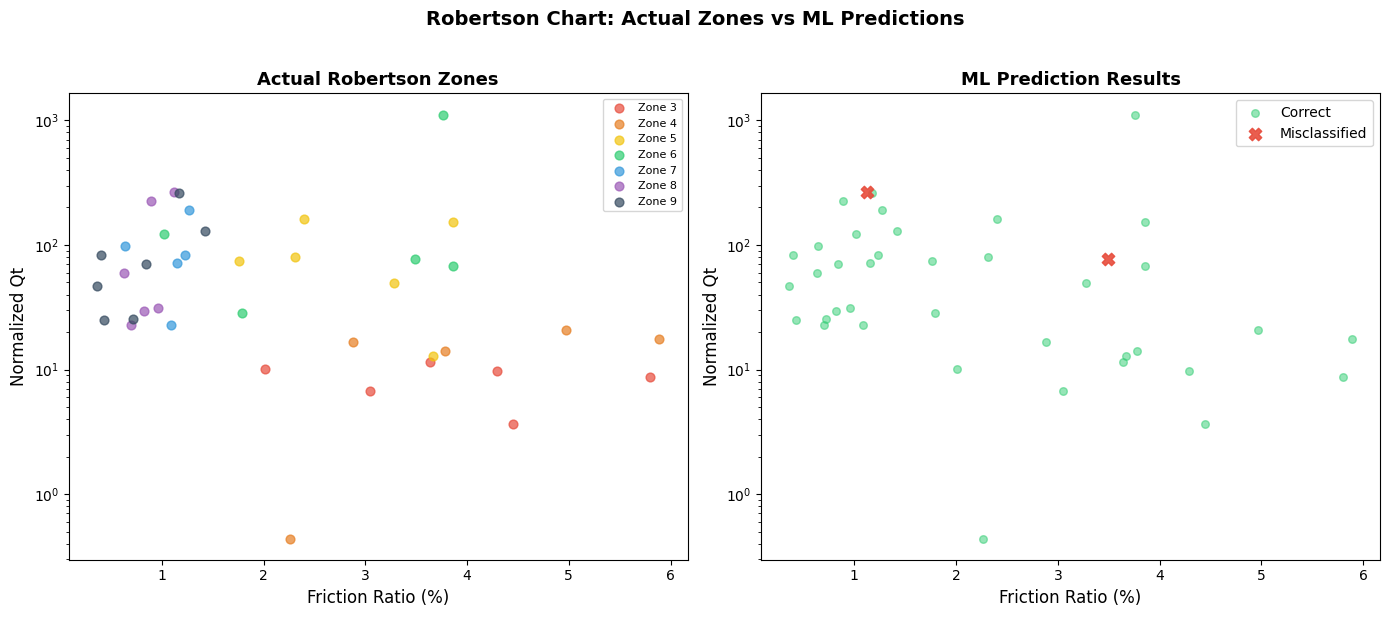

Correctly classified: 38/40 (95.0%)
Misclassifications cluster at zone boundaries (expected).


In [8]:
# ─────────────────────────────────────────────────────
# VISUALIZE ML PREDICTIONS ON ROBERTSON CHART
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

X_test_df = pd.DataFrame(X_test, columns=features)
correct_mask = y_test.values == y_pred_best

# Actual zones
for zone in zone_labels:
    mask = y_test.values == zone
    axes[0].scatter(X_test_df.loc[mask, 'friction_ratio'].values,
                     X_test_df.loc[mask, 'normalized_qc'].values,
                     alpha=0.7, s=40, color=zone_colors.get(zone, 'gray'),
                     label=f'Zone {zone}')
axes[0].set_xlabel('Friction Ratio (%)', fontsize=12)
axes[0].set_ylabel('Normalized Qt', fontsize=12)
axes[0].set_title('Actual Robertson Zones', fontsize=13, fontweight='bold')
axes[0].set_yscale('log')
axes[0].legend(fontsize=8)

# ML predictions (correct vs misclassified)
axes[1].scatter(X_test_df.loc[correct_mask, 'friction_ratio'].values,
                X_test_df.loc[correct_mask, 'normalized_qc'].values,
                alpha=0.5, s=30, color='#2ecc71', label='Correct', marker='o')
axes[1].scatter(X_test_df.loc[~correct_mask, 'friction_ratio'].values,
                X_test_df.loc[~correct_mask, 'normalized_qc'].values,
                alpha=0.9, s=80, color='#e74c3c', label='Misclassified', marker='X')
axes[1].set_xlabel('Friction Ratio (%)', fontsize=12)
axes[1].set_ylabel('Normalized Qt', fontsize=12)
axes[1].set_title('ML Prediction Results', fontsize=13, fontweight='bold')
axes[1].set_yscale('log')
axes[1].legend(fontsize=10)

plt.suptitle('Robertson Chart: Actual Zones vs ML Predictions',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Correctly classified: {correct_mask.sum()}/{len(y_test)} ({correct_mask.mean()*100:.1f}%)")
print("Misclassifications cluster at zone boundaries (expected).")

---

## Part 8: Depth Profile with Predicted Zones

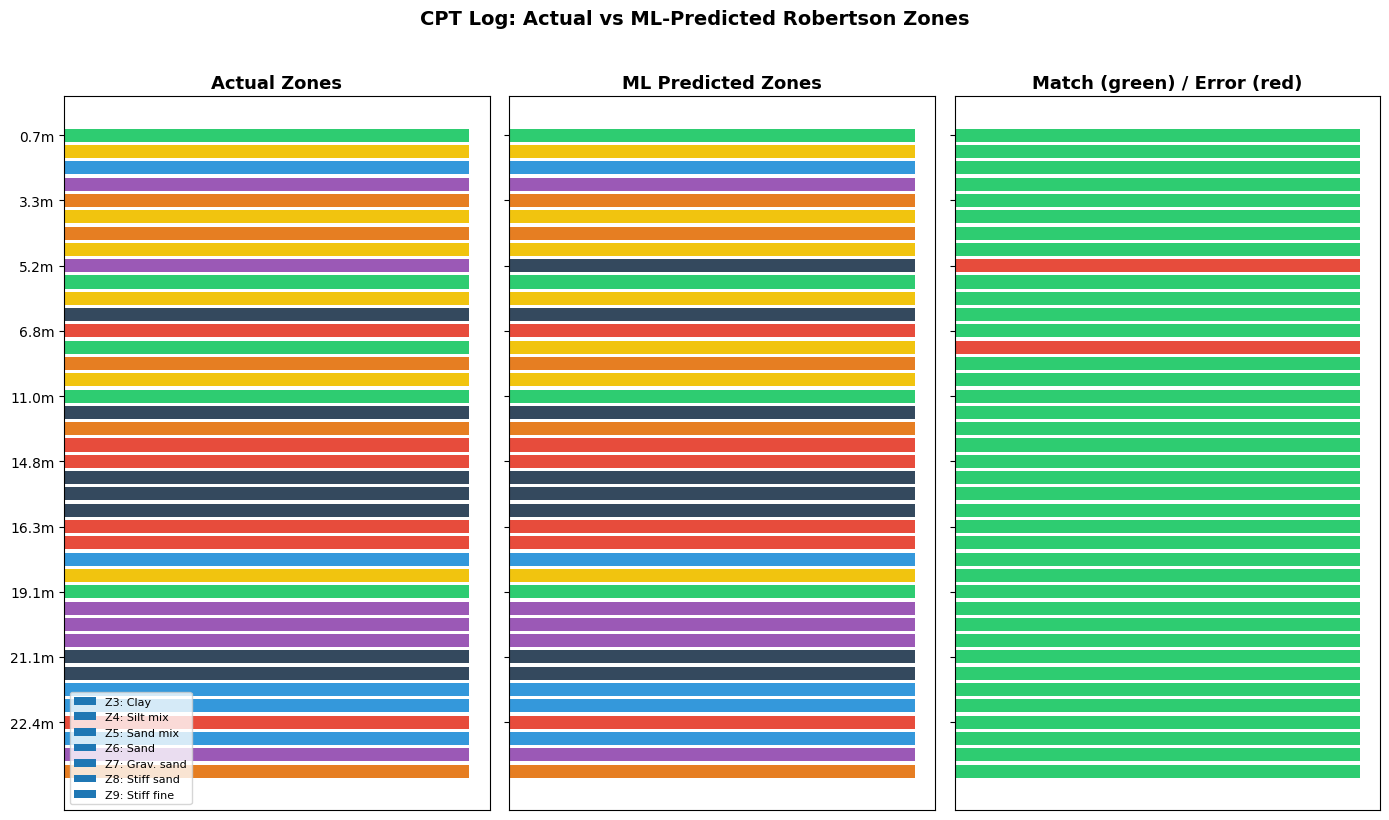

In [9]:
# ─────────────────────────────────────────────────────
# CPT LOG — Predicted zones along depth
# ─────────────────────────────────────────────────────

# Sort test data by depth
test_order = np.argsort(X_test_df['depth'].values)
depth_sorted = X_test_df['depth'].values[test_order]
actual_sorted = y_test.values[test_order]
pred_sorted = y_pred_best[test_order]

fig, axes = plt.subplots(1, 3, figsize=(14, 8), sharey=True)

# Actual zone profile
actual_colors = [zone_colors.get(z, 'gray') for z in actual_sorted]
axes[0].barh(range(len(depth_sorted)), [1]*len(depth_sorted),
             color=actual_colors, edgecolor='none')
axes[0].set_yticks(range(0, len(depth_sorted), max(1, len(depth_sorted)//10)))
axes[0].set_yticklabels([f'{d:.1f}m' for d in depth_sorted[
    range(0, len(depth_sorted), max(1, len(depth_sorted)//10))]])
axes[0].set_title('Actual Zones', fontsize=13, fontweight='bold')
axes[0].invert_yaxis()
axes[0].set_xticks([])

# Predicted zone profile
pred_colors = [zone_colors.get(z, 'gray') for z in pred_sorted]
axes[1].barh(range(len(depth_sorted)), [1]*len(depth_sorted),
             color=pred_colors, edgecolor='none')
axes[1].set_title('ML Predicted Zones', fontsize=13, fontweight='bold')
axes[1].set_xticks([])

# Match/mismatch
match_colors = ['#2ecc71' if a == p else '#e74c3c'
                for a, p in zip(actual_sorted, pred_sorted)]
axes[2].barh(range(len(depth_sorted)), [1]*len(depth_sorted),
             color=match_colors, edgecolor='none')
axes[2].set_title('Match (green) / Error (red)', fontsize=13, fontweight='bold')
axes[2].set_xticks([])

# Legend
for zone, color in zone_colors.items():
    axes[0].barh([], [], color=color, label=f'Z{zone}: {zone_names[zone]}')
axes[0].legend(fontsize=8, loc='lower left')

plt.suptitle('CPT Log: Actual vs ML-Predicted Robertson Zones',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## Practice Exercises

### Exercise 1: Simplified 3-Class Problem
Group Robertson zones into 3 categories: Clay (3-4), Mixed (5), Sand/Gravel (6-9). How does accuracy change?

### Exercise 2: Remove Ic as Feature
Since Ic is derived from other CPT parameters, try removing it. How much does accuracy drop? Is the model learning the Ic formula?

### Exercise 3: Probability Estimates
Use a model with `predict_proba()` to identify low-confidence predictions. Plot confidence vs depth.

In [10]:
# EXERCISE 2 STARTER:
# features_no_ic = [f for f in features if f != 'soil_behavior_type_index_Ic']
# X_no_ic = df[features_no_ic]
# X_train_ni, X_test_ni, y_train_ni, y_test_ni = train_test_split(
#     X_no_ic, y, test_size=0.2, random_state=42, stratify=y)
# rf_no_ic = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42)
# rf_no_ic.fit(scaler.fit_transform(X_train_ni), y_train_ni)
# y_pred_ni = rf_no_ic.predict(scaler.transform(X_test_ni))
# print(f"With Ic:    {accuracy_score(y_test, y_pred_best):.4f}")
# print(f"Without Ic: {accuracy_score(y_test_ni, y_pred_ni):.4f}")

---

## Key Takeaways

1. **CPT data** provides continuous subsurface profiling through qc, fs, and u2 measurements.

2. **Robertson zones** classify soil behavior into 9 types based on normalized CPT parameters.

3. **ML classification** can automate Robertson zone interpretation, potentially outperforming simple Ic-threshold rules.

4. **Misclassifications cluster at zone boundaries** — where soil behavior transitions are gradual, not abrupt.

5. **Feature importance** confirms Ic, friction ratio, and cone resistance are the key discriminators.

6. CPT log visualization with predicted zones enables **rapid quality checking** of ML-automated interpretation.

---

## How This Connects to ML

| Today's Concept | ML Equivalent |
|----------------|---------------|
| Robertson chart zones | Multi-class labels |
| Ic thresholds | Rule-based baseline classifier |
| ML zone classification | Data-driven multi-class classifier |
| Zone boundary confusion | Decision boundary uncertainty |
| CPT profile visualization | Spatial prediction display |
| Feature importance | Model interpretability |

---

*Day 059 of 100 — ML reads the cone like a seasoned engineer!*